# Roster Updates

A daily check-in on your team, built on free NBA data (no Yahoo access needed):

1. **Health**: each player's status from the **official NBA injury report** (published every 15 minutes during the season).
2. **Recent form**: last few games vs. last season's averages, to spot hot streaks and minutes changes.
3. **Summary**: one table with an alert per player.

Your team comes from the draft tool's saved picks (`data/draft_picks.json`), or from `MY_TEAM` in Settings.
Run All to refresh.

## Settings

In [71]:
SEASON = "2026-27"            # current season
BASELINE_SEASON = "2025-26"   # recent form is compared against these per-game averages; SEASON = this season so far
LAST_N = 5                    # recent-form window, in games
MINUTES_ALERT = 4             # flag a minutes change of this many per game vs. the baseline
REPORT_LOOKBACK_HOURS = 48    # how far back to look for the latest injury report

MY_TEAM = [
    # leave empty to use your picks from the draft tool, or list names to override, e.g. "Tyrese Maxey",
]

# Player values for the team profile and injury replacements (same model as the draft tool, src/fantasy_core.py)
VALUE_SEASON = SEASON         # season being valued (falls back to last season if it has no games yet)
# How player values are blended (rank_roster, team profile, replacements). Switches automatically:
VALUE_SWITCH_AFTER = "2m"     # mid-season blend once this season has this much data (first game -> latest game)
VALUE_EARLY_BASE = "2m"       # early season: 30% last 2 months of LAST season ...
VALUE_EARLY_WEIGHT = 0.7      # ... + 70% this season so far (weight of this season)
VALUE_MID_BASE = "2m"         # mid-season: last 2 months of this season ...
VALUE_MID_RECENT = "2w"       # ... blended with its last 2 weeks
VALUE_MID_WEIGHT = 0.3        # weight of the last 2 weeks (70/30)
VALUE_MIN_GAMES = 10          # games needed in the 2-month base window
VALUE_RECENT_MIN_GAMES = 2    # games needed in the other part (this season so far / last 2 weeks) for it to count
NUM_TEAMS = 14
ROSTER_SIZE = 10
GAIN_SCALE = 3.0              # diminishing returns: the higher a team category already is, the less extra adds
PROTECT_TOP_Z = 7             # rank_roster: your top N by Z_TOTAL are never flagged WEAKEST (highlighted green)
RANK_PUNT = []                # categories ignored entirely by rank_roster and recommend (e.g. ["FG%", "FT%"])
# Default weights for rank_roster, recommend and the weakest-player check:
# FG%/FT% x0.5, TO x0.8, the other six x1.2 (adjustments must sum to 0)
DEFAULT_WEIGHTS = {"FG%": -0.5, "FT%": -0.5, "TO": -0.2,
                   "3PM": 0.2, "PTS": 0.2, "REB": 0.2, "AST": 0.2, "STL": 0.2, "BLK": 0.2}

# Recommendations (after the roster ranking): values from each player's most recent regular-season games
RECO_COUNT = 6                # free agents to recommend
RECO_LAST_N = 10              # each player's last N games of this season (SEASON only)
RECO_MIN_GAMES = 2            # games this season needed to be valued; raise it as the season goes on (e.g. 5)
RECO_STALE_DAYS = 30          # don't recommend players whose last game is older than this (vs. the league's latest game)

## Load my team

In [72]:
import difflib
import io
import json
import sys
import time
import unicodedata
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd
import pdfplumber
import requests
from nba_api.stats.endpoints import leaguedashplayerstats, playergamelogs, playerindex

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT / "src"))
import importlib
import fantasy_core
importlib.reload(fantasy_core)  # pick up edits to src/fantasy_core.py without restarting the kernel
from fantasy_core import clean_daily_caches, previous_season, season_stats
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)
TODAY = pd.Timestamp.now(tz="America/New_York")


def cached(name, fetch, refresh=False):
    path = DATA / name
    if path.exists() and not refresh:
        return pd.read_csv(path)
    df = fetch()
    df.to_csv(path, index=False)
    time.sleep(0.6)  # be polite to NBA.com
    return df


def norm(name):
    """Accent-, punctuation- and case-insensitive key for matching names across sources."""
    name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in name.lower() if ch.isalnum())


def initial_matches(name, candidates):
    """'b williams' / 'B. Williams' -> players whose first name starts with B and last name matches 'williams'."""
    parts = name.replace(".", " ").split()
    if len(parts) < 2 or len(norm(parts[0])) != 1:
        return []
    first, last = norm(parts[0]), norm(" ".join(parts[1:]))
    hits = [n for n in candidates
            if norm(n.split()[0]).startswith(first) and last in norm(" ".join(n.split()[1:]))]
    # Prefer exact last names ('z williams' -> Ziaire Williams, not Zion Williamson); suffixes like Jr./III are ignored
    suffixes = ("jr", "sr", "ii", "iii", "iv")
    exact = [n for n in hits if norm(" ".join(w for w in n.split()[1:] if norm(w) not in suffixes)) == last
             or norm(" ".join(n.split()[1:])) == last]
    return exact or hits


def match_name(name, candidates, cutoff=0.75):
    """Match a typed name within a list of names: exact, initial + last name, unique partial, then closest spelling."""
    names = {norm(n): n for n in candidates}
    key = norm(name)
    if key in names:
        return names[key], None
    initials = initial_matches(name, names.values())
    if len(initials) == 1:
        return initials[0], None
    partial = initials or [n for k, n in names.items() if key in k]
    if len(partial) == 1:
        return partial[0], None
    if partial:
        return None, f"'{name}' is ambiguous: {partial[:6]}"
    close = difflib.get_close_matches(key, list(names), n=1, cutoff=cutoff)
    return (names[close[0]], None) if close else (None, f"'{name}' not found")


picks_file = DATA / "draft_picks.json"
picks = json.loads(picks_file.read_text(encoding="utf-8")) if picks_file.exists() else {"taken": [], "mine": [], "history": []}

# Current rosters (team, position) - refreshed once a day to catch trades and signings
index = cached(f"player_index_{SEASON}_{TODAY:%Y-%m-%d}.csv",
               lambda: playerindex.PlayerIndex(season=SEASON, timeout=60).get_data_frames()[0])
index["PLAYER_NAME"] = index["PLAYER_FIRST_NAME"] + " " + index["PLAYER_LAST_NAME"]
by_key = {norm(n): row for n, row in zip(index["PLAYER_NAME"], index.to_dict("records"))}
removed = clean_daily_caches(DATA)  # this season's data is re-downloaded daily; drop older copies


def build_my_team():
    """Your roster with current NBA team and position (MY_TEAM overrides the saved picks)."""
    return pd.DataFrame([{
        "PLAYER_NAME": name,
        "PLAYER_ID": by_key.get(norm(name), {}).get("PERSON_ID"),
        "TEAM": by_key.get(norm(name), {}).get("TEAM_ABBREVIATION", "?"),
        "POSITION": by_key.get(norm(name), {}).get("POSITION", "?"),
    } for name in (MY_TEAM or picks["mine"])])


my_team = build_my_team()
missing = my_team.loc[my_team["PLAYER_ID"].isna(), "PLAYER_NAME"].tolist()
print(f"{len(my_team)} players on your team" + (f"; not found on a {SEASON} roster: {missing}" if missing else ""))
my_team

14 players on your team


,PLAYER_NAME,PLAYER_ID,TEAM,POSITION
0,Tyrese Maxey,1630178,PHI,G
1,Trae Young,1629027,WAS,G
2,Donovan Clingan,1642270,POR,C
3,Nickeil Alexander-Walker,1629638,ATL,G
4,Joel Embiid,203954,PHI,C-F
5,Paul George,202331,BOS,F
6,Ausar Thompson,1641709,DET,G-F
7,Precious Achiuwa,1630173,SAC,F
8,Julian Champagnie,1630577,SAS,F
9,Brook Lopez,201572,LAC,C


## Health: official NBA injury report

The NBA publishes an injury report every 15 minutes (US Eastern time) during the season, listing every player who is
**Out, Doubtful, Questionable, Probable or Available** for that day's and the next day's games, with the reason.
This finds the newest one and reads it.

- Players **not on the report** are healthy, or their team isn't playing in the window it covers.
- Reports start with the regular season; in the preseason and offseason none are published.
- `G League - Two-Way` / `On Assignment` entries are roster moves, not injuries.

In [73]:
HEADERS = {"User-Agent": "Mozilla/5.0"}
REPORT_URL = "https://ak-static.cms.nba.com/referee/injury/Injury-Report_{}.pdf"
COLUMNS = ["GAME_DATE", "GAME_TIME", "MATCHUP", "TEAM", "PLAYER", "STATUS", "REASON"]


def latest_report(hours=REPORT_LOOKBACK_HOURS):
    """Newest report URL and time, checking 15-minute slots backwards from now (US Eastern)."""
    now = TODAY.floor("15min")
    slots = [now - pd.Timedelta(minutes=15 * i) for i in range(hours * 4)]
    url = lambda t: REPORT_URL.format(f"{t:%Y-%m-%d_%I_%M%p}")
    exists = lambda t: requests.head(url(t), headers=HEADERS, timeout=20).status_code == 200
    with ThreadPoolExecutor(16) as pool:
        for start in range(0, len(slots), 16):
            batch = slots[start:start + 16]
            for t, ok in zip(batch, pool.map(exists, batch)):
                if ok:
                    return url(t), t
    return None, None


def _lines(words, tol=2):
    """Group PDF words into text lines by vertical position."""
    lines = []
    for w in sorted(words, key=lambda w: (w["top"], w["x0"])):
        if lines and abs(w["top"] - lines[-1][0]) <= tol:
            lines[-1][1].append(w)
        else:
            lines.append([w["top"], [w]])
    return lines


def parse_report(pdf_bytes):
    """One row per listed player. Columns are found from the header line; wrapped reasons are re-joined."""
    rows, carry, bounds = [], dict.fromkeys(COLUMNS[:4], ""), None
    with pdfplumber.open(io.BytesIO(pdf_bytes)) as pdf:
        for page in pdf.pages:
            words = page.extract_words(x_tolerance=1)
            anchor = next((w for w in words if w["text"] == "Matchup"), None)
            header_top = 0
            if anchor:
                header_top = anchor["top"]
                on_header = [w for w in words if abs(w["top"] - header_top) < 3]
                header = {w["text"]: w["x0"] for w in on_header}
                game_x = sorted(w["x0"] for w in on_header if w["text"] == "Game")
                if len(game_x) == 2 and all(t in header for t in ("Team", "Player", "Current", "Reason")):
                    bounds = [x - 4 for x in [game_x[1], header["Matchup"], header["Team"], header["Player"],
                                              header["Current"], header["Reason"]]]
            if bounds is None:
                continue

            page_rows, fragments = [], []
            for top, line in _lines([w for w in words if w["top"] > header_top + 5]):
                text = " ".join(w["text"] for w in line)
                if text.startswith(("Page", "Injury Report:")):
                    continue
                cells = dict.fromkeys(COLUMNS, "")
                for w in line:
                    col = COLUMNS[sum(w["x0"] >= b for b in bounds)]
                    cells[col] = f"{cells[col]} {w['text']}".strip()
                for c in COLUMNS[:4]:
                    if cells[c]:
                        carry[c] = cells[c]
                if cells["PLAYER"]:
                    page_rows.append({**carry, "PLAYER": cells["PLAYER"], "STATUS": cells["STATUS"], "_top": top,
                                      "_reason": [(top, cells["REASON"])] if cells["REASON"] else []})
                elif cells["REASON"] and "NOT YET SUBMITTED" not in cells["REASON"].upper():
                    fragments.append((top, cells["REASON"]))
            for top, frag in fragments:  # wrapped reason lines belong to the nearest player row
                if page_rows:
                    min(page_rows, key=lambda r: abs(r["_top"] - top))["_reason"].append((top, frag))
            for r in page_rows:
                r["REASON"] = " ".join(f for _, f in sorted(r.pop("_reason")))
                r.pop("_top")
            rows += page_rows

    df = pd.DataFrame(rows, columns=COLUMNS)
    # "Allen, Jarrett" -> "Jarrett Allen"; "Moore Jr., Wendell" -> "Wendell Moore Jr."
    df["PLAYER"] = df["PLAYER"].str.split(",", n=1).map(lambda p: f"{p[1].strip()} {p[0].strip()}" if len(p) == 2 else p[0])
    return df


report_url, report_time = latest_report()
if report_url:
    report = parse_report(requests.get(report_url, headers=HEADERS, timeout=30).content)
    print(f"Injury report: {report_time:%a %b %d, %I:%M %p} ET  ({len(report)} players listed, "
          f"games {', '.join(sorted(report['GAME_DATE'].unique()))})")
else:
    report = pd.DataFrame(columns=COLUMNS)
    print(f"No injury report published in the last {REPORT_LOOKBACK_HOURS} hours "
          "(normal in the preseason/offseason; reports start with the regular season).")

report_by_key = {norm(p): r for p, r in zip(report["PLAYER"], report.to_dict("records"))}
health = my_team[["PLAYER_NAME", "TEAM"]].copy()
health["STATUS"] = [report_by_key.get(norm(n), {}).get("STATUS", "Not on report") for n in health["PLAYER_NAME"]]
health["REASON"] = [report_by_key.get(norm(n), {}).get("REASON", "") for n in health["PLAYER_NAME"]]
health["GAME"] = [" ".join(filter(None, [report_by_key.get(norm(n), {}).get(k, "") for k in ("GAME_DATE", "MATCHUP")]))
                  for n in health["PLAYER_NAME"]]
health

Injury report: Tue Nov 10, 12:45 PM ET  (46 players listed, games 11/10/2026)


,PLAYER_NAME,TEAM,STATUS,REASON,GAME
0,Tyrese Maxey,PHI,Not on report,,
1,Trae Young,WAS,Not on report,,
2,Donovan Clingan,POR,Not on report,,
3,Nickeil Alexander-Walker,ATL,Not on report,,
4,Joel Embiid,PHI,Not on report,,
5,Paul George,BOS,Not on report,,
6,Ausar Thompson,DET,Not on report,,
7,Precious Achiuwa,SAC,Not on report,,
8,Julian Champagnie,SAS,Not on report,,
9,Brook Lopez,LAC,Not on report,,


### Injury replacements

`replacements("embiid", "trae young")` takes the names of your injured players (partial names and missing accents are fine) and:

1. **Shows your team category profile without them**: bars are the healthy team, tick marks `|` are your full team,
   so you can see which categories you lose.
2. **Recommends 3 free agents per injured player** who add the most to the weakened team, at any position
   (`match_position=True` limits them to players sharing a position with the injured player). Each candidate is scored by how much they improve the team profile **with
   diminishing returns** (`GAIN_SCALE`): adding to a category you're weak in counts more than padding one you
   already lead. The candidate's injury risk (`AVAIL`) is included. A free agent is recommended for only one injured player.
   `GAIN` is measured against picking up a typical (median) free agent; `HELPS` / `HURTS` show the
   categories the player moves most for your team (free agents are usually below the league average in several categories).

With no names, it uses your players marked **Out** or **Doubtful** on the latest injury report.

**`compare=["al horford", "gary payton"]`** adds a separate table with those players scored the same way, so you can
check a name you're considering against the recommendations. It works for any player with values: `STATUS` shows
whether they're a free agent, taken, or yours, and `FA_RANK` where they'd rank among all free agents for your team.

**Free agents** = players on a current NBA roster who aren't in your draft file's picks (yours or other teams').
That stands in for your league's waiver wire until Yahoo API access is approved, so drops and adds made in Yahoo
aren't reflected; double-check availability in Yahoo before claiming.
Player values blend automatically by season phase (`VALUE_*` settings): **early season** (under 2 months of games) = 30% last season's final 2 months + 70% this season so far; **mid-season** = 70% this season's last 2 months + 30% its last 2 weeks. The log line under the roster ranking shows which blend was used.

In [74]:
import difflib

import matplotlib.pyplot as plt
import numpy as np

from fantasy_core import CATS, LABELS, POSITIONS, draw_profile, player_values, positions_of
from fantasy_core import season_span, window_offset


def value_blend(season):
    """Today's blend: early season = VALUE_EARLY_WEIGHT of this season so far + the rest from last season's final
    VALUE_EARLY_BASE; mid-season (VALUE_SWITCH_AFTER of games played) = this season's last VALUE_MID_BASE,
    with VALUE_MID_WEIGHT on its last VALUE_MID_RECENT."""
    first, latest = season_span(DATA, season, in_progress=season == SEASON)
    if first is not None and latest >= first + window_offset(VALUE_SWITCH_AFTER):
        return "mid-season", dict(base_season=None, base_months=VALUE_MID_BASE,
                                  recent_months=VALUE_MID_RECENT, recent_weight=VALUE_MID_WEIGHT)
    return "early season", dict(base_season=previous_season(season), base_months=VALUE_EARLY_BASE,
                                recent_months=None, recent_weight=VALUE_EARLY_WEIGHT)


def load_values(season):
    phase, blend = value_blend(season)
    print(f"Value blend for {season}: {phase}")
    return player_values(DATA, season=season, num_teams=NUM_TEAMS, roster_size=ROSTER_SIZE,
                         min_games=VALUE_MIN_GAMES, recent_min_games=VALUE_RECENT_MIN_GAMES,
                         in_progress=season == SEASON, **blend)


values_season = VALUE_SEASON
try:
    values = load_values(values_season)
except ValueError as err:  # e.g. the season hasn't started yet
    values_season = previous_season(VALUE_SEASON)
    print(f"{err}; using {values_season} for player values instead")
    values = load_values(values_season)
values["KEY"] = values["PLAYER_NAME"].map(norm)
values["TEAM"] = values["KEY"].map(lambda k: by_key.get(k, {}).get("TEAM_ABBREVIATION"))  # current team
values["POSITION"] = values["KEY"].map(lambda k: by_key.get(k, {}).get("POSITION"))

def refresh_pool(verbose=True):
    """Recompute who's yours, who's taken and who's a free agent (call after roster changes)."""
    global my_keys, rostered, free_agents
    my_keys = {norm(n) for n in my_team["PLAYER_NAME"]}
    rostered = my_keys | {norm(n) for n in picks["taken"]}
    free_agents = values[~values["KEY"].isin(rostered) & values["TEAM"].notna()]
    if verbose:
        print(f"{len(free_agents)} free agents with {values_season} stats on current NBA rosters")


refresh_pool()


def find_mine(name):
    """Match a typed name to one of your players (initials like 'b williams' work)."""
    player, err = match_name(name, my_team["PLAYER_NAME"], cutoff=0.6)
    if err:
        print(f"  {err} on your team. Skipped.")
    return player


def find_player(name):
    """Match a typed name to any player with values (initials like 'b williams' work)."""
    player, err = match_name(name, values["PLAYER_NAME"])
    if err:
        print(f"  {err} among players with {values_season} values. Skipped.")
    return player


def team_gain(team_tot, z):
    """Per-category improvement with diminishing returns: GAIN_SCALE * tanh(total / GAIN_SCALE)."""
    f = lambda x: GAIN_SCALE * np.tanh(x / GAIN_SCALE)
    return f(team_tot.values + z) - f(team_tot.values)


def helps_hurts(gain_row):
    helps = ", ".join(f"{LABELS[c]} {g:+.2f}" for c, g in gain_row.nlargest(3).items() if g > 0)
    hurts = ", ".join(f"{LABELS[c]} {g:+.2f}" for c, g in gain_row.nsmallest(2).items() if g < -0.05) or "-"
    return helps, hurts


TABLE_COLS = ["PLAYER_NAME", "TEAM", "POSITION", "AVAIL", "ADJ_TOTAL", "GAIN", "HELPS", "HURTS"]
TABLE_FMT = {"AVAIL": "{:.0%}", "ADJ_TOTAL": "{:.2f}", "GAIN": "{:+.2f}", "FA_RANK": "{:.0f}"}


def replacements(*injured, n=3, match_position=False, compare=None):
    if not injured:
        injured = health.loc[health["STATUS"].isin(["Out", "Doubtful"]), "PLAYER_NAME"].tolist()
        if not injured:
            print("No names given and none of your players are Out/Doubtful on the latest report. "
                  "Try replacements(\"name\", ...).")
            return
        print(f"From the injury report: {', '.join(injured)}")
    out = [p for p in map(find_mine, injured) if p]
    if not out:
        return
    out_keys = {norm(p) for p in out}

    mine_vals = values[values["KEY"].isin(my_keys)]
    full_tot = mine_vals[CATS].sum()
    healthy_tot = mine_vals[~mine_vals["KEY"].isin(out_keys)][CATS].sum()
    no_value = [p for p in my_team["PLAYER_NAME"] if norm(p) not in set(values["KEY"])]
    if no_value:
        print(f"No {values_season} values for (left out of the profile): {', '.join(no_value)}")

    # 1. Team profile without the injured players
    order = healthy_tot.sort_values().index
    span = max(1.0, full_tot.abs().max(), healthy_tot.abs().max())
    fig, ax = plt.subplots(figsize=(7, 3.8), facecolor="#fcfcfb")
    draw_profile(ax, healthy_tot, order, f"Team without {', '.join(out)}", span, before=full_tot)
    ax.set_xlabel("summed z-score   (bars = without injured,  | = full team)", color="#898781", fontsize=9)
    plt.tight_layout()
    plt.show()

    # 2. Replacements: free agents ranked by gain to the weakened team (expected contribution = z x AVAIL)
    z = values[CATS].to_numpy() * values[["AVAIL"]].to_numpy()
    gains = pd.DataFrame(team_gain(healthy_tot, z), columns=CATS, index=values.index)
    total_gain = gains.sum(axis=1)
    used = set()
    for player in out:
        pos = positions_of(by_key.get(norm(player), {}).get("POSITION", "")) if match_position else []
        eligible = free_agents["POSITION"].map(lambda p: bool(set(positions_of(p)) & set(pos)) if pos else True)
        cands = free_agents[eligible & ~free_agents.index.isin(used)].copy()
        # Gain vs. picking up a typical (median) free agent, so the best options read as positive
        cands["GAIN"] = total_gain[cands.index] - total_gain[cands.index].median()
        top = cands.nlargest(n, "GAIN")
        used |= set(top.index)
        top["HELPS"], top["HURTS"] = zip(*[helps_hurts(gains.loc[i]) for i in top.index])
        print(f"\nReplacing {player} ({'/'.join(POSITIONS[p] for p in pos) or 'any position'}):")
        display(top[TABLE_COLS].reset_index(drop=True).style.format(TABLE_FMT))

    # 3. Your own comparison list, scored the same way (any player, rostered or not)
    if compare:
        names = [p for p in map(find_player, compare) if p]
        if not names:
            return
        fa_gain = total_gain[free_agents.index]
        table = values[values["PLAYER_NAME"].isin(names)].copy()
        table = table.set_index("PLAYER_NAME").loc[list(dict.fromkeys(names))].reset_index()  # keep your order
        idx = values.index[values["PLAYER_NAME"].isin(names)]
        by_name = dict(zip(values.loc[idx, "PLAYER_NAME"], idx))
        table["GAIN"] = [total_gain[by_name[p]] - fa_gain.median() for p in table["PLAYER_NAME"]]
        table["HELPS"], table["HURTS"] = zip(*[helps_hurts(gains.loc[by_name[p]]) for p in table["PLAYER_NAME"]])
        table["STATUS"] = ["yours" if norm(p) in my_keys else "taken" if norm(p) in rostered
                           else "free agent" if norm(p) in set(free_agents["KEY"]) else "not on a roster"
                           for p in table["PLAYER_NAME"]]
        # Where the player would rank among all free agents for this team (1 = best)
        table["FA_RANK"] = [int((fa_gain > total_gain[by_name[p]]).sum()) + 1 for p in table["PLAYER_NAME"]]
        print("\nYour comparison list (GAIN vs. a typical free agent; FA_RANK = rank among free agents):")
        display(table[["PLAYER_NAME", "STATUS", *TABLE_COLS[1:6], "FA_RANK", "HELPS", "HURTS"]]
                .style.format(TABLE_FMT))

Value blend for 2026-27: early season
Player values from: 30% last 2 months of 2025-26 + 70% 2026-27 season so far (season in progress, refreshed daily)
273 free agents with 2026-27 stats on current NBA rosters


In [75]:
INJURED = ['k flipowski', 'mob hinsonody']   # e.g. ["embiid", "trae young"]; leave empty to use your Out/Doubtful players from the injury report
COMPARE = ['aday mara', 'y missi', 'j grant', 's pippen jr', 'b lopez', 'b simmons']   # e.g. ["al horford", "gary payton"]: players to score side by side with the recommendations
replacements(*INJURED, compare=COMPARE)

  'k flipowski' not found on your team. Skipped.
  'mob hinsonody' not found on your team. Skipped.


## Transactions

Record pickups, drops and other teams' moves so your roster and the free-agent pool stay current.
Changes are saved to `data/draft_picks.json` (shared with the draft tool).

```python
transaction(add="champagnie", drop="konchar", mine=True)   # your move
transaction(add="horford", drop="aldama", mine=False)      # another team's move
```

| | `mine=True` (your team) | `mine=False` (another team) |
|---|---|---|
| `drop` | leaves your roster, back to the free-agent pool | leaves the taken list, back to the free-agent pool |
| `add`  | joins your roster, out of the free-agent pool | joins the taken list, out of the free-agent pool |

- Either side can be left empty (a pure pickup or a pure drop). Partial names and missing accents are fine.
- Nothing is saved unless the whole move is valid (e.g. you can't add a player who's already on a team, or drop one who isn't).
- `undo_transaction()` reverts the last transaction.
- `where_is("b williams")` shows every matching player and where they are (your roster, another team, or free agent,
  plus their NBA team). A transaction whose name isn't found on the side you chose prints the same, and changes nothing.
- Initials work: `"b williams"` or `"B. Williams"` means a first name starting with B and last name Williams.
- The free-agent pool and `replacements()` update immediately; re-run the Health and Recent form cells (or Run All) to refresh those tables.

In [76]:
BACKUP_FILE = DATA / "draft_picks.bak.json"


def where_is(name, show=True):
    """Every player matching `name`, anywhere: your roster, other teams, or free agents (with their NBA team)."""
    pool = {norm(n): n for n in list(index["PLAYER_NAME"]) + picks["taken"] + picks["mine"]}  # league spelling wins
    key = norm(name)
    hits = ([pool[key]] if key in pool else initial_matches(name, pool.values())
            or [n for k, n in pool.items() if key in k]
            or [pool[k] for k in difflib.get_close_matches(key, list(pool), n=3, cutoff=0.75)])
    mine_keys, taken_keys = {norm(n) for n in picks["mine"]}, {norm(n) for n in picks["taken"]}
    lines = []
    for n in hits:
        k = norm(n)
        league = "YOUR roster" if k in mine_keys else "another team" if k in taken_keys else "free agent"
        nba = by_key.get(k, {}).get("TEAM_ABBREVIATION") or "not on an NBA roster"
        lines.append(f"{n} ({nba}): {league}")
    if show:
        print(f"'{name}':\n  " + ("\n  ".join(lines) if lines else "no matching player"))
    return lines


def save_picks():
    picks_file.write_text(json.dumps(picks, ensure_ascii=False, indent=2), encoding="utf-8")


def transaction(add="", drop="", mine=True):
    global my_team
    side, who = ("mine", "your roster") if mine else ("taken", "other teams")
    owned = {norm(n) for n in picks["mine"] + picks["taken"]}

    # Validate both sides first; nothing changes unless the whole move is valid
    errors, add_name, drop_name = [], None, None
    if drop.strip():
        drop_name, err = match_name(drop, picks[side])
        if err:
            errors.append(f"drop: {err} on {who}")
            errors += [f"    where '{drop}' is: {line}" for line in where_is(drop, show=False)]
    if add.strip():
        # Prefer the stats spelling (matches the draft tool), else today's NBA rosters (e.g. rookies)
        pool = list(dict.fromkeys(list(values["PLAYER_NAME"]) + list(index["PLAYER_NAME"])))
        add_name, err = match_name(add, pool)
        if err:
            errors.append(f"add: {err}")
            errors += [f"    where '{add}' is: {line}" for line in where_is(add, show=False)]
        elif norm(add_name) in owned and norm(add_name) != norm(drop_name or ""):
            owner = "your roster" if norm(add_name) in {norm(n) for n in picks["mine"]} else "another team"
            errors.append(f"add: {add_name} is already on {owner}")
    if not (add_name or drop_name) and not errors:
        print("Nothing to do: give add=, drop= or both.")
        return
    if errors:
        print("No changes made:\n  " + "\n  ".join(errors))
        return

    BACKUP_FILE.write_text(picks_file.read_text(encoding="utf-8"), encoding="utf-8")
    picks.setdefault("history", [])
    if drop_name:
        picks[side].remove(drop_name)
        picks["history"].append(f"{'DROP' if mine else 'FREED':6} {drop_name}")
    if add_name:
        picks[side].append(add_name)
        picks["history"].append(f"{'ADD' if mine else 'TAKEN':6} {add_name}")
    save_picks()

    my_team = build_my_team()
    refresh_pool(verbose=False)
    moves = [f"dropped {drop_name}" if drop_name else "", f"added {add_name}" if add_name else ""]
    print(f"{'You' if mine else 'Another team'}: {' and '.join(m for m in moves if m)}  "
          f"(your roster: {len(picks['mine'])} players; free agents: {len(free_agents)})")
    if MY_TEAM:
        print("Note: MY_TEAM is set in Settings, so your roster in this notebook still comes from that list.")


def undo_transaction():
    """Restore the picks file from before the last transaction."""
    global picks, my_team
    if not BACKUP_FILE.exists():
        print("Nothing to undo.")
        return
    picks_file.write_text(BACKUP_FILE.read_text(encoding="utf-8"), encoding="utf-8")
    BACKUP_FILE.unlink()
    picks = json.loads(picks_file.read_text(encoding="utf-8"))
    my_team = build_my_team()
    refresh_pool(verbose=False)
    print(f"Last transaction undone. Your roster: {len(picks['mine'])} players; free agents: {len(free_agents)}.")

In [77]:
# ---- Enter a transaction, then Shift+Enter ----
# transaction(add="strus", drop="goodwin", mine=True)   # e.g. transaction(add="horford", drop="hinson", mine=True)
transaction(add="kalkbrenner", drop="hezonja", mine=False) 
print("Your roster:", ", ".join(picks["mine"]))

No changes made:
  drop: 'hezonja' not found on other teams
      where 'hezonja' is: Mario Hezonja (CLE): free agent
  add: Ryan Kalkbrenner is already on another team
Your roster: Tyrese Maxey, Trae Young, Donovan Clingan, Nickeil Alexander-Walker, Joel Embiid, Paul George, Ausar Thompson, Precious Achiuwa, Julian Champagnie, Brook Lopez, De'Anthony Melton, Zaccharie Risacher, Reed Sheppard, Kevin Huerter


## Recent form

Each player's last `LAST_N` games this season (regular season once it starts, preseason until then)
compared with their `BASELINE_SEASON` per-game averages. A big **minutes** change is the most useful signal:
it usually means a new role (starter, bench, injury fill-in) rather than a hot or cold streak.
Preseason games are lightly played, so treat them as a rough hint only.

In [78]:
STAT_COLS = ["MIN", "PTS", "REB", "AST", "STL", "BLK", "FG3M", "TOV"]


def game_logs():
    """This season's game logs for every player: regular season if it has started, else preseason."""
    for season_type in ["Regular Season", "Pre Season"]:
        logs = playergamelogs.PlayerGameLogs(season_nullable=SEASON, season_type_nullable=season_type,
                                             timeout=60).get_data_frames()[0]
        time.sleep(0.6)
        if len(logs):
            return logs, season_type
    return pd.DataFrame(), None


logs, season_type = game_logs()
baseline_season = BASELINE_SEASON
baseline = season_stats(DATA, baseline_season, in_progress=baseline_season == SEASON)
if baseline.empty:  # e.g. the season hasn't started yet
    baseline_season = previous_season(BASELINE_SEASON)
    print(f"No {BASELINE_SEASON} regular-season games yet; comparing against {baseline_season} instead")
    baseline = season_stats(DATA, baseline_season)
baseline = baseline.set_index("PLAYER_ID")

rows = []
for p in my_team.itertuples():
    games = logs[logs["PLAYER_ID"] == p.PLAYER_ID].sort_values("GAME_DATE", ascending=False).head(LAST_N) if len(logs) else logs
    row = {"PLAYER_NAME": p.PLAYER_NAME, "GP": len(games),
           "LAST_GAME": pd.Timestamp(games["GAME_DATE"].iloc[0]).strftime("%b %d") if len(games) else "-"}
    if len(games):
        row.update(games[STAT_COLS].mean().round(1).to_dict())
        row["FG%"] = round(games["FGM"].sum() / games["FGA"].sum(), 3) if games["FGA"].sum() else None
        row["FT%"] = round(games["FTM"].sum() / games["FTA"].sum(), 3) if games["FTA"].sum() else None
    if p.PLAYER_ID in baseline.index:
        row["MIN_CHANGE"] = round(row["MIN"] - baseline.loc[p.PLAYER_ID, "MIN"], 1) if len(games) else None
        row["PTS_CHANGE"] = round(row["PTS"] - baseline.loc[p.PLAYER_ID, "PTS"], 1) if len(games) else None
    rows.append(row)
form = pd.DataFrame(rows)

print(f"Last {LAST_N} games of the {SEASON} {season_type.lower()}" if season_type else f"No {SEASON} games played yet")
(form.style.format(precision=1, na_rep="-", subset=[c for c in form.columns if c not in ("PLAYER_NAME", "GP", "LAST_GAME")])
     .background_gradient(cmap="RdYlGn", vmin=-8, vmax=8, subset=[c for c in ["MIN_CHANGE", "PTS_CHANGE"] if c in form]))

Last 5 games of the 2026-27 regular season


,PLAYER_NAME,GP,LAST_GAME,MIN,PTS,REB,AST,STL,BLK,FG3M,TOV,FG%,FT%,MIN_CHANGE,PTS_CHANGE
0,Tyrese Maxey,5,Nov 08,35.2,25.4,3.2,6.6,1.0,0.4,2.6,1.6,0.5,0.9,-2.8,-2.9
1,Trae Young,5,Nov 09,34.3,16.0,2.6,7.0,1.4,0.2,2.0,4.0,0.4,0.7,8.7,-1.9
2,Donovan Clingan,5,Nov 07,25.1,13.6,10.8,1.0,0.4,2.0,1.0,1.8,0.6,0.8,-2.1,1.5
3,Nickeil Alexander-Walker,5,Nov 09,32.4,25.6,3.4,2.6,1.6,0.4,5.0,2.2,0.4,1.0,-1.0,4.8
4,Joel Embiid,5,Nov 08,29.0,15.0,9.4,3.6,0.8,0.6,0.0,3.0,0.3,1.0,-2.6,-11.9
5,Paul George,5,Nov 08,29.1,19.0,4.6,4.6,2.4,0.8,3.4,3.4,0.5,0.7,-1.6,1.7
6,Ausar Thompson,5,Nov 09,27.6,10.2,9.4,4.0,1.2,0.4,0.0,2.0,0.5,0.7,1.6,0.3
7,Precious Achiuwa,5,Nov 08,25.4,7.0,7.2,1.4,0.6,1.8,0.4,2.0,0.5,0.6,1.5,-3.1
8,Julian Champagnie,5,Nov 09,22.8,8.2,4.8,1.4,0.6,0.0,2.2,0.8,0.4,0.8,-4.8,-2.9
9,Brook Lopez,5,Nov 08,24.7,14.4,5.8,0.6,0.6,0.8,1.2,1.0,0.6,0.6,2.9,5.9


## Roster ranking: who contributes most

Ranks your players by **`CONTRIB`: how much your team's category profile would drop without them**, using the same
model and diminishing returns as `replacements()` (`VALUE_SEASON` values, `GAIN_SCALE`). It's based on per-game
production only: **availability (`AVAIL`) is not used** (shown for reference); `availability=True` discounts for games likely missed.
That's more useful than a plain z-score total because it accounts for **fit**: a shot-blocker on a team already strong
in blocks adds less than the same player on a team that's thin there. `Z_TOTAL` (the player's own weighted z-score sum)
is shown alongside for reference.

- The category columns show where each player's contribution comes from (green = helps, red = costs your team).
- `weights={"3PM": -0.4, "STL": 0.2, "TO": 0.2}` re-prioritizes categories exactly like the draft tool's `best_available`:
  each category starts at 1.0, your number is added, and the adjustments must sum to 0. Both `CONTRIB` and `Z_TOTAL` use them.
- Your **3 weakest contributors** (`weakest=` to change) are flagged and highlighted: the first players to consider
  dropping or streaming over. Players without values (e.g. rookies) are listed at the bottom, unranked.
- All 9 categories count here and in Recommendations, weighted by `DEFAULT_WEIGHTS` in Settings (default: FG% and FT% x0.5, TO x0.8, the other six x1.2). `RANK_PUNT` can still ignore a category entirely (empty by default).
- Your top `PROTECT_TOP_Z` (7) players by `Z_TOTAL` are **green** (`TOP 7 Z`) and are never flagged as weakest; the weakest are picked from everyone else.

In [79]:
from fantasy_core import KEY_TO_CAT, parse_weights

PUNT_CATS = [KEY_TO_CAT[k.lower()] for k in RANK_PUNT]  # ignored by rank_roster and recommend


def rank_roster(weights=None, weakest=3, availability=False, protect=None):
    protect = PROTECT_TOP_Z if protect is None else protect  # top N by Z_TOTAL can't be flagged WEAKEST
    weights = DEFAULT_WEIGHTS if weights is None else weights  # default from Settings
    mult = parse_weights(weights, punt=PUNT_CATS)
    w = np.array([mult[c] for c in CATS])
    mine_vals = values[values["KEY"].isin(my_keys)]
    if mine_vals.empty:
        print(f"None of your players have {values_season} values yet (VALUE_MIN_GAMES = {VALUE_MIN_GAMES}). "
              "Lower VALUE_MIN_GAMES or use last season's values.")
        return
    expected = mine_vals[CATS].to_numpy()  # per-game z-scores
    if availability:
        expected = expected * mine_vals[["AVAIL"]].to_numpy()  # discount for games likely missed
    team = expected.sum(axis=0)
    f = lambda x: GAIN_SCALE * np.tanh(x / GAIN_SCALE)
    per_cat = (f(team) - f(team - expected)) * w  # what the team loses in each category without the player

    table = mine_vals[["PLAYER_NAME", "TEAM", "POSITION", "GP", "AVAIL"]].copy()
    table[[LABELS[c] for c in CATS]] = per_cat
    table["CONTRIB"] = per_cat.sum(axis=1)
    table["Z_TOTAL"] = (mine_vals[CATS].to_numpy() * w).sum(axis=1)
    table = table.sort_values("CONTRIB", ascending=False).reset_index(drop=True)
    table.insert(0, "RANK", range(1, len(table) + 1))
    table["FLAG"] = ""
    top_z = table["Z_TOTAL"].nlargest(protect).index if protect else table.index[:0]
    table.loc[top_z, "FLAG"] = f"TOP {protect} Z"
    candidates = table.index[~table.index.isin(top_z)]  # still sorted by CONTRIB
    table.loc[candidates[-weakest:], "FLAG"] = "WEAKEST"

    unvalued = [p for p in my_team["PLAYER_NAME"] if norm(p) not in my_keys & set(values["KEY"])]
    if unvalued:
        extra = my_team[my_team["PLAYER_NAME"].isin(unvalued)][["PLAYER_NAME", "TEAM", "POSITION"]].assign(FLAG="no values")
        table = pd.concat([table, extra], ignore_index=True)

    if PUNT_CATS:
        print("Ignoring: " + ", ".join(LABELS[c] for c in PUNT_CATS) + " (RANK_PUNT)")
    if weights:
        print("Weights: " + ", ".join(f"{LABELS[c]} x{m:g}" for c, m in mult.items() if m not in (0, 1))
              + " (all others x1)")
    global LAST_WEAKEST
    weak = table.loc[table["FLAG"] == "WEAKEST", "PLAYER_NAME"].tolist()
    LAST_WEAKEST = weak  # highlighted again in the Recommendations table
    last = values.attrs.get("last_game")
    print(f"Values: {values.attrs.get('source', '?')}; "
          f"last game considered: {last:%a %b %d, %Y}" if last is not None else "last game considered: unknown")
    print(f"Weakest {len(weak)} contributors: {', '.join(weak)}")

    cat_cols = [LABELS[c] for c in CATS if c not in PUNT_CATS]
    table = table.drop(columns=[LABELS[c] for c in PUNT_CATS])  # ignored categories aren't shown
    span = max(0.1, np.nanmax(np.abs(table[cat_cols].to_numpy(dtype=float))))
    colors = {"WEAKEST": "background-color: #fde2e1; font-weight: bold", f"TOP {protect} Z": "background-color: #dcfce7"}
    highlight = lambda row: [colors.get(row["FLAG"], "") for _ in row]
    return (table.style
            .format({"AVAIL": "{:.0%}", "GP": "{:.0f}", "CONTRIB": "{:+.2f}", "Z_TOTAL": "{:+.2f}",
                     **{c: "{:+.2f}" for c in cat_cols}}, na_rep="-")
            .background_gradient(cmap="RdYlGn", vmin=-span, vmax=span, subset=cat_cols)
            .apply(highlight, axis=1, subset=["RANK", "PLAYER_NAME", "TEAM", "POSITION", "GP", "AVAIL",
                                              "CONTRIB", "Z_TOTAL", "FLAG"])
            .hide(axis="index"))

In [80]:
# RANK_WEIGHTS = {"AST": 0.1, "BLK": 0.1, "TO": -0.2}   # e.g. {"3PM": -0.4, "STL": 0.2, "TO": 0.2}; must sum to 0
RANK_WEIGHTS = DEFAULT_WEIGHTS   # default from Settings (FG%/FT% x0.5, TO x0.8, others x1.2); {} = all equal
rank_roster(weights=RANK_WEIGHTS)

Weights: FG% x0.5, FT% x0.5, 3PM x1.2, PTS x1.2, REB x1.2, AST x1.2, STL x1.2, BLK x1.2, TO x0.8 (all others x1)
Values: 30% last 2 months of 2025-26 + 70% 2026-27 season so far; last game considered: Mon Nov 09, 2026
Weakest 3 contributors: Kevin Huerter, Zaccharie Risacher, Brook Lopez


RANK,PLAYER_NAME,TEAM,POSITION,GP,AVAIL,FG%,FT%,3PM,PTS,REB,AST,STL,BLK,TO,CONTRIB,Z_TOTAL,FLAG
1,Paul George,BOS,F,9,58%,-0.03,-0.10,+1.83,+0.11,-0.09,+0.01,+2.60,-0.42,-0.23,+3.68,+3.56,TOP 7 Z
2,Nickeil Alexander-Walker,ATL,G,12,87%,-0.07,+0.29,+2.25,+0.14,-0.63,-0.13,+0.73,-0.47,-0.04,+2.07,+1.62,TOP 7 Z
3,Tyrese Maxey,PHI,G,11,81%,-0.03,+0.33,+0.88,+0.21,-0.44,+0.20,+0.73,-0.03,-0.07,+1.78,+4.03,TOP 7 Z
4,Donovan Clingan,POR,C,9,82%,+0.05,-0.44,-0.53,-0.17,+0.53,-0.39,-1.42,+2.81,+0.22,+0.65,+1.32,TOP 7 Z
5,Reed Sheppard,HOU,G,8,84%,-0.12,+0.06,+0.99,-0.23,-0.92,-0.08,+0.73,-0.57,+0.28,+0.13,-2.19,
6,De'Anthony Melton,GSW,G,11,68%,-0.08,+0.02,+0.32,-0.25,-0.36,-0.23,+0.91,-0.38,+0.15,+0.08,-2.19,
7,Julian Champagnie,SAS,F,11,88%,-0.02,+0.04,+1.05,-0.28,-0.29,-0.42,-0.72,-0.21,+0.76,-0.11,-2.08,
8,Joel Embiid,PHI,C-F,9,59%,-0.14,+0.39,-0.96,+0.11,+0.42,+0.04,-0.92,+0.39,-0.29,-0.96,-0.13,TOP 7 Z
9,Ausar Thompson,DET,G-F,9,80%,+0.01,-0.43,-1.39,-0.36,+0.25,+0.07,+0.73,+0.16,-0.12,-1.07,-2.01,
10,Trae Young,WAS,G,11,48%,-0.12,+0.12,+0.17,+0.05,-0.74,+0.34,-0.13,-0.65,-0.31,-1.27,-0.91,TOP 7 Z


## Weakest contributors: keep or trade?

A closer look at the players flagged **WEAKEST** in the roster ranking, game by game this season.

**Per-game value (`GAME_Z`)** scores each game like the rankings do: every category as a z-score against the games
of a typical rostered player (the top `NUM_TEAMS × ROSTER_SIZE` players by minutes), weighted by `DEFAULT_WEIGHTS`,
FG%/FT% by shot volume and turnovers counted against. 0 = a typical rostered player's average game.

One chart compares the players (up to 3 per chart). In each stat, a **normal distribution is fitted** to each player's
games (their average and spread) and drawn as a smooth curve with a translucent fill in their color; the **peak is the
player's average** and a wider curve means less consistent games. **Ticks below the axis** are the actual games
(the fit is a simplification, e.g. blocks are mostly 0s and 1s). The **dashed line** is a typical rostered player's average. In the `GAME_Z` panel, the **dotted line** is the level of the
best available free agents (the average of the top `RECO_COUNT` free agents' season `GAME_Z`).

**Verdict rules** (simple, stated with each verdict):
- **KEEP**: averages at or above the free-agent level, or is clearly trending up (last `TREND_GAMES` games `TREND_UP`+
  above the earlier ones, or minutes up `MINUTES_ALERT`+).
- **TRADE / DROP**: below the free-agent level and losing `MINUTES_ALERT`+ minutes with a falling trend (a shrinking role),
  or below it by `TRADE_GAP`+ with good games (`GAME_Z` ≥ 0) under 30% of the time and no upward trend.
- Trends compare **medians** (the typical game), so one big or awful night doesn't decide them.
- **MONITOR**: everything in between.

Early in the season samples are small (`GP`); treat verdicts on fewer than 8 games as low-confidence.

In [81]:
from fantasy_core import BASE, GRID, INK, INK_2, MUTED, POS, SURFACE

TREND_GAMES = 5    # "recent" = each player's last N games when judging the trend
TREND_UP = 2.0     # recent GAME_Z this much above earlier games = trending up (about 1 SD of normal swings)
TRADE_GAP = 1.0    # TRADE / DROP needs to average this far below the free-agent level

season_game_logs = cached(f"game_logs_{SEASON}_{TODAY:%Y-%m-%d}.csv", lambda: playergamelogs.PlayerGameLogs(
    season_nullable=SEASON, season_type_nullable="Regular Season", timeout=120).get_data_frames()[0])
GAME_COLS = ["MIN", "PTS", "REB", "AST", "STL", "BLK", "FG3M", "TOV", "FGM", "FGA", "FTM", "FTA"]
HIST_PANELS = [("GAME_Z", "Per-game value"), ("PTS", "PTS"), ("REB", "REB"), ("AST", "AST"), ("STL", "STL"),
               ("BLK", "BLK"), ("FG3M", "3PM"), ("TOV", "TO"), ("FG_PCT", "FG%"), ("FT_PCT", "FT%")]


def game_values(logs):
    """Per-game z-score value of every game, against a typical rostered player's per-game averages."""
    logs = logs.copy()
    logs["GAME_DATE"] = pd.to_datetime(logs["GAME_DATE"])
    logs[GAME_COLS] = logs[GAME_COLS].apply(pd.to_numeric)
    avgs = logs.groupby("PLAYER_ID")[GAME_COLS].mean()
    pool_ids = avgs[logs.groupby("PLAYER_ID").size() >= 2].nlargest(NUM_TEAMS * ROSTER_SIZE, "MIN").index
    pool = logs[logs["PLAYER_ID"].isin(pool_ids)]  # every game played by a typical rostered player
    mult = parse_weights(DEFAULT_WEIGHTS, punt=PUNT_CATS)
    z = pd.DataFrame(index=logs.index)
    for c in ["PTS", "REB", "AST", "STL", "BLK", "FG3M", "TOV"]:
        z[c] = (logs[c] - pool[c].mean()) / pool[c].std()  # vs how much single games vary
    z["TOV"] = -z["TOV"]
    for pct, (made, att) in {"FG_PCT": ("FGM", "FGA"), "FT_PCT": ("FTM", "FTA")}.items():
        lg = pool[made].sum() / pool[att].sum()
        pool_impact = pool[made] - lg * pool[att]
        z[pct] = ((logs[made] - lg * logs[att]) - pool_impact.mean()) / pool_impact.std()
        logs[pct] = logs[made] / logs[att].where(logs[att] > 0)  # per-game percentage, for the histogram
    logs["GAME_Z"] = sum(z[c] * mult[c] for c in CATS)
    reference = {c: pool[c].mean() for c in ["PTS", "REB", "AST", "STL", "BLK", "FG3M", "TOV"]}
    reference.update(FG_PCT=pool["FGM"].sum() / pool["FGA"].sum(), FT_PCT=pool["FTM"].sum() / pool["FTA"].sum(), GAME_Z=0.0)
    return logs, reference


def verdict(g, fa_level):
    """KEEP / MONITOR / TRADE / DROP from the game distribution (g = one player's games, oldest first)."""
    n, mean, good = len(g), g["GAME_Z"].mean(), (g["GAME_Z"] >= 0).mean()
    recent, earlier = g.tail(TREND_GAMES), g.iloc[:-TREND_GAMES]
    # Medians, so one big (or awful) night doesn't decide the trend
    trend = recent["GAME_Z"].median() - earlier["GAME_Z"].median() if len(earlier) >= 2 else 0.0
    min_change = recent["MIN"].mean() - earlier["MIN"].mean() if len(earlier) >= 2 else 0.0
    gap = mean - fa_level
    facts = (f"avg {mean:+.2f} vs free agents {fa_level:+.2f}; good games {good:.0%}; "
             f"trend {trend:+.2f} (median), minutes {min_change:+.1f} (last {TREND_GAMES} vs earlier)")
    if gap >= 0:
        call, why = "KEEP", "averages at or above what the best free agents offer"
    elif trend >= TREND_UP or min_change >= MINUTES_ALERT:
        call, why = "KEEP", "trending up - recent games or minutes are clearly better than earlier"
    elif min_change <= -MINUTES_ALERT and trend < 0:
        call, why = "TRADE / DROP", "below the free-agent level and losing minutes - the role is shrinking"
    elif gap <= -TRADE_GAP and good < 0.30 and trend <= 0:
        call, why = "TRADE / DROP", "below the free-agent level, rarely has a good game, and isn't improving"
    else:
        call, why = "MONITOR", "below the free-agent level, but not clearly enough to move on yet"
    if n < 8:
        why += f" (low confidence: only {n} games)"
    return {"GP": n, "AVG_GAME_Z": mean, "MEDIAN": g["GAME_Z"].median(), "GOOD_GAMES": good,
            "BEST": g["GAME_Z"].max(), "TREND": trend, "MIN_CHANGE": min_change, "VS_FREE_AGENTS": gap,
            "VERDICT": call, "WHY": f"{why}. {facts}"}


PLAYER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # chart palette slots 1-3 (blue, orange, aqua), in this fixed order


def normal_pdf(x, mean, sd):
    return np.exp(-0.5 * ((x - mean) / sd) ** 2) / (sd * np.sqrt(2 * np.pi))


def plot_comparison(games, reference, fa_level):
    """One figure comparing up to 3 players: per stat, a normal distribution fitted to each player's games
    (smooth curve + translucent fill), with every actual game as a tick below the axis."""
    names = list(games)[:3]
    fig, axes = plt.subplots(4, 3, figsize=(15, 15), facecolor=SURFACE)
    for ax, (col, label) in zip(axes.flat, HIST_PANELS):
        ax.set_facecolor(SURFACE)
        fits = {}
        for n in names:
            vals = games[n][col].dropna()
            if len(vals) >= 2 and vals.std() > 0:
                fits[n] = (vals, vals.mean(), vals.std())
        if not fits:
            ax.axis("off")
            continue
        # x range: 3 SD either side of every player, plus the reference lines; percentages stay in 0-1, counts >= 0
        lo = min(m - 3 * sd for _, m, sd in fits.values())
        hi = max(m + 3 * sd for _, m, sd in fits.values())
        lo, hi = min(lo, reference[col]), max(hi, reference[col])
        if col == "GAME_Z":
            lo, hi = min(lo, fa_level), max(hi, fa_level)
        elif col in ("FG_PCT", "FT_PCT"):
            lo, hi = 0.0, 1.0
        else:
            lo = max(lo, 0.0)
        x = np.linspace(lo, hi, 400)
        peak = max(normal_pdf(m, m, sd) for _, m, sd in fits.values())
        for j, n in enumerate(names):
            color = PLAYER_COLORS[j]
            if n in fits:
                vals, m, sd = fits[n]
                y = normal_pdf(x, m, sd)
                ax.fill_between(x, y, color=color, alpha=0.18, linewidth=0)
                ax.plot(x, y, color=color, linewidth=2.2)
            else:
                vals = games[n][col].dropna()
            # every actual game, as a short tick under the axis (one row per player)
            ax.scatter(vals, np.full(len(vals), -peak * (0.06 + 0.06 * j)), marker="|", s=90, linewidths=1.6,
                       color=color, clip_on=False)
        ax.axvline(reference[col], color=MUTED, linewidth=1.8, linestyle="--")
        if col == "GAME_Z":
            ax.axvline(fa_level, color=INK_2, linewidth=1.8, linestyle=":")
        ax.set_xlim(lo, hi)
        ax.set_ylim(-peak * 0.24, peak * 1.12)
        ax.set_yticks([])
        ax.axhline(0, color=BASE, linewidth=1)
        ax.set_title(label, loc="left", color=INK, fontsize=12)
        ax.tick_params(colors=MUTED, labelsize=9, length=0)
        for side in ["top", "right", "left", "bottom"]:
            ax.spines[side].set_visible(False)
    for ax in axes.flat[len(HIST_PANELS):]:
        ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=PLAYER_COLORS[j], alpha=0.6, label=f"{n} ({len(games[n])} games)")
               for j, n in enumerate(names)]
    handles += [plt.Line2D([], [], color=INK_2, linewidth=2.2, label="curve = fitted normal (peak = average)"),
                plt.Line2D([], [], color=INK_2, marker="|", linestyle="", markersize=10, label="ticks below = actual games"),
                plt.Line2D([], [], color=MUTED, linewidth=1.8, linestyle="--", label="typical rostered player"),
                plt.Line2D([], [], color=INK_2, linewidth=1.8, linestyle=":", label="best free agents (per-game value)")]
    fig.suptitle("Weakest contributors: fitted distribution of their games this season",
                 x=0.01, y=0.995, ha="left", color=INK, fontsize=14)
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 0.97), ncol=4, frameon=False,
               fontsize=10, labelcolor=INK)
    plt.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()


def analyze_weakest(players=None, plots=True):
    """Keep-or-trade check for the weakest contributors (default: the ones flagged by rank_roster)."""
    players = players or LAST_WEAKEST
    if not players:
        print("No weakest players flagged yet - run the roster ranking first.")
        return
    logs, reference = game_values(season_game_logs)
    id_of = dict(zip(logs["PLAYER_NAME"], logs["PLAYER_ID"]))

    # Free-agent level: average season GAME_Z of the best RECO_COUNT free agents with RECO_MIN_GAMES+ games
    season_z = logs.groupby("PLAYER_ID").agg(GAME_Z=("GAME_Z", "mean"), GP=("GAME_Z", "size"),
                                              PLAYER_NAME=("PLAYER_NAME", "first"))
    keys = season_z["PLAYER_NAME"].map(norm)
    fa = season_z[(season_z["GP"] >= RECO_MIN_GAMES) & ~keys.isin(rostered)
                  & keys.map(lambda k: by_key.get(k, {}).get("TEAM_ABBREVIATION")).notna()]
    fa_level = fa["GAME_Z"].nlargest(RECO_COUNT).mean()

    rows, games = [], {}
    for name in players:
        match, _ = match_name(name, list(id_of))  # partial names / initials work
        pid = id_of.get(match)
        name = match or name
        g = logs[logs["PLAYER_ID"] == pid].sort_values("GAME_DATE") if pid is not None else logs.iloc[0:0]
        if g.empty:
            rows.append({"PLAYER_NAME": name, "VERDICT": "-", "WHY": f"no {SEASON} games yet"})
            continue
        rows.append({"PLAYER_NAME": name, **verdict(g, fa_level)})
        games[name] = g
    if plots and games:
        names = list(games)
        for i in range(0, len(names), 3):  # 3 players per chart (one color each)
            plot_comparison({n: games[n] for n in names[i:i + 3]}, reference, fa_level)
    table = pd.DataFrame(rows)
    colors = {"KEEP": "background-color: #dcfce7", "MONITOR": "background-color: #fef3c7",
              "TRADE / DROP": "background-color: #fde2e1; font-weight: bold"}
    return (table.style
            .format({"AVG_GAME_Z": "{:+.2f}", "MEDIAN": "{:+.2f}", "GOOD_GAMES": "{:.0%}", "BEST": "{:+.2f}",
                     "TREND": "{:+.2f}", "MIN_CHANGE": "{:+.1f}", "VS_FREE_AGENTS": "{:+.2f}", "GP": "{:.0f}"}, na_rep="-")
            .apply(lambda r: [colors.get(r["VERDICT"], "") if col in ("PLAYER_NAME", "VERDICT") else "" for col in r.index], axis=1)
            .set_properties(subset=["WHY"], **{"text-align": "left", "white-space": "normal"})
            .hide(axis="index"))

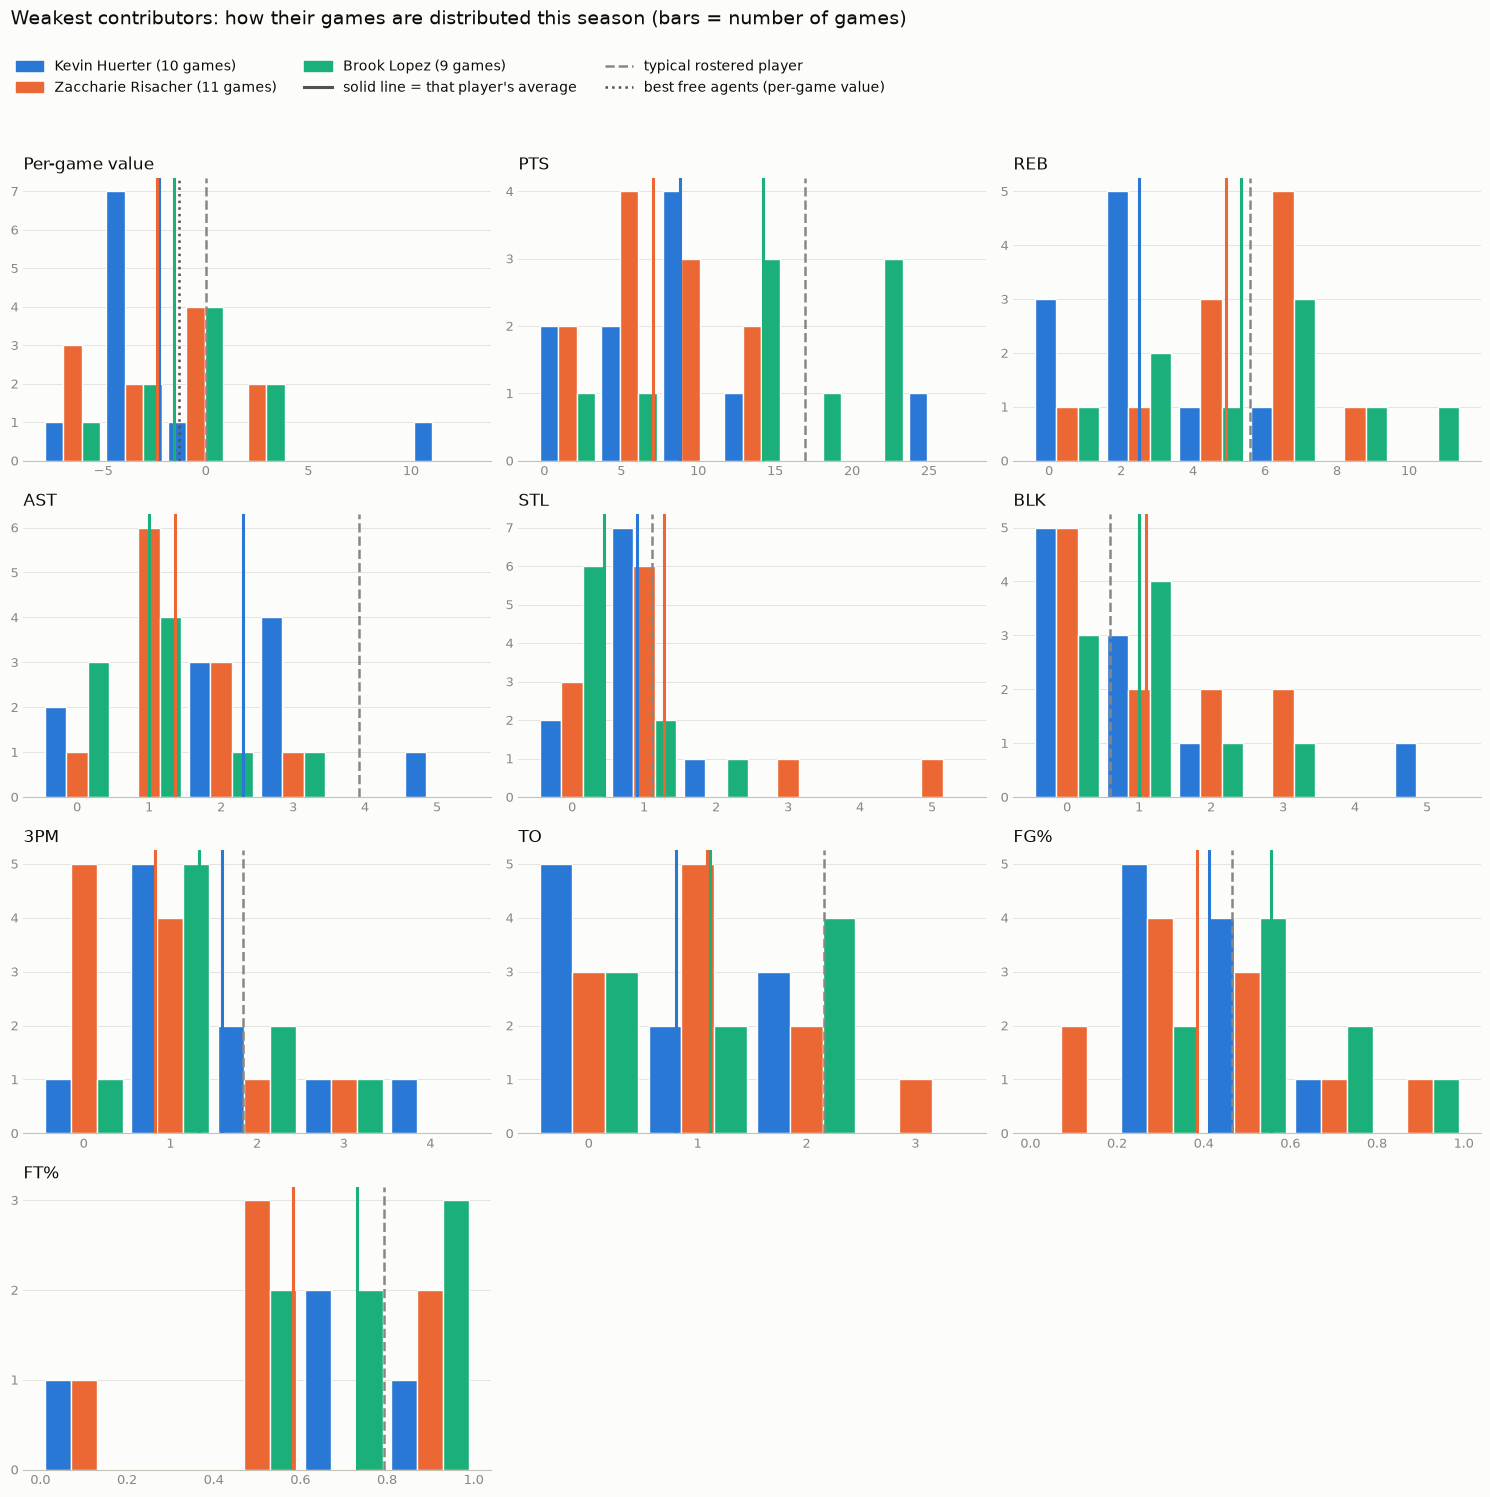

PLAYER_NAME,GP,AVG_GAME_Z,MEDIAN,GOOD_GAMES,BEST,TREND,MIN_CHANGE,VS_FREE_AGENTS,VERDICT,WHY
Kevin Huerter,10,-2.26,-3.64,10%,+10.22,+1.17,+6.2,-0.95,KEEP,"trending up - recent games or minutes are clearly better than earlier. avg -2.26 vs free agents -1.31; good games 10%; trend +1.17 (median), minutes +6.2 (last 5 vs earlier)"
Zaccharie Risacher,11,-2.38,-1.14,18%,+2.10,-6.06,-11.5,-1.07,TRADE / DROP,"below the free-agent level and losing minutes - the role is shrinking. avg -2.38 vs free agents -1.31; good games 18%; trend -6.06 (median), minutes -11.5 (last 5 vs earlier)"
Brook Lopez,9,-1.57,-1.17,33%,+1.61,-0.96,+1.8,-0.26,MONITOR,"below the free-agent level, but not clearly enough to move on yet. avg -1.57 vs free agents -1.31; good games 33%; trend -0.96 (median), minutes +1.8 (last 5 vs earlier)"


In [82]:
analyze_weakest()   # or analyze_weakest(["risacher", "huerter"]) for specific players

## Recommendations

Ranks **your roster, the top `RECO_COUNT` free agents, and any players you name** in one table, using each player's
**games this season only**: their last `RECO_LAST_N` regular-season games of `SEASON`
(last season and the preseason are not used; players with fewer than `RECO_MIN_GAMES` games this season
aren't valued yet). `GP_USED`, `LAST_GAME` and `DAYS_SINCE` (days before the league's most recent game)
show the sample. Free agents who haven't played in `RECO_STALE_DAYS`
days (long injuries, out of the rotation) aren't recommended, but you can still `INCLUDE` them.

**`MARGINAL`** = your team with the player minus your team without them, with the same diminishing returns and
`RANK_WEIGHTS` as the roster ranking (availability not used). For your players that's what you'd lose; for everyone
else, what you'd gain by adding them, so the whole table is on one scale. Category columns show where it comes from.

- **Red rows** = the weakest players flagged in the roster ranking above; **blue rows** = recommended and named players.
  The `FLAG` column says the same in words.
- `INCLUDE` adds specific players (free agents, other teams' players or your own) to compare.
- Free agents = on a current NBA roster and not in your league's picks file (see Transactions).

In [83]:
from fantasy_core import zscores

LOG_COLS = ["PLAYER_ID", "PLAYER_NAME", "GAME_DATE", "MIN", "PTS", "REB", "AST", "STL", "BLK", "FG3M", "TOV",
            "FGM", "FGA", "FTM", "FTA"]


def season_logs(season, in_progress):
    """Regular-season game logs for every player (a season in progress is re-downloaded daily)."""
    tag = f"_{TODAY:%Y-%m-%d}" if in_progress else ""
    return cached(f"game_logs_{season}{tag}.csv", lambda: playergamelogs.PlayerGameLogs(
        season_nullable=season, season_type_nullable="Regular Season", timeout=120).get_data_frames()[0])


# Each player's last RECO_LAST_N regular-season games of this season only
current_logs = season_logs(SEASON, in_progress=True)
logs_all = current_logs.reindex(columns=LOG_COLS).copy()
logs_all["GAME_DATE"] = pd.to_datetime(logs_all["GAME_DATE"])
logs_all[LOG_COLS[3:]] = logs_all[LOG_COLS[3:]].apply(pd.to_numeric)  # an empty current season would leave them as text
last_games = logs_all.sort_values("GAME_DATE", ascending=False).groupby("PLAYER_ID").head(RECO_LAST_N)
recent = last_games.groupby("PLAYER_ID").agg(
    PLAYER_NAME=("PLAYER_NAME", "first"), GP_USED=("GAME_DATE", "size"), LAST_GAME=("GAME_DATE", "max"),
    **{c: (c, "mean") for c in LOG_COLS[3:]}).reset_index()
recent = recent[recent["GP_USED"] >= RECO_MIN_GAMES].reset_index(drop=True)
LATEST_GAME = logs_all["GAME_DATE"].max()
recent["DAYS_SINCE"] = (LATEST_GAME - recent["LAST_GAME"]).dt.days  # how stale the sample is
for pct, (made, att) in {"FG_PCT": ("FGM", "FGA"), "FT_PCT": ("FTM", "FTA")}.items():
    recent[pct] = (recent[made] / recent[att].where(recent[att] > 0)).fillna(0)
z = zscores(recent, NUM_TEAMS * ROSTER_SIZE, [c for c in CATS if c not in PUNT_CATS])
recent[CATS + ["TOTAL"]] = z[CATS + ["TOTAL"]]  # per-game stats -> category z-scores
recent["KEY"] = recent["PLAYER_NAME"].map(norm)
recent["TEAM"] = recent["KEY"].map(lambda k: by_key.get(k, {}).get("TEAM_ABBREVIATION"))
recent["POSITION"] = recent["KEY"].map(lambda k: by_key.get(k, {}).get("POSITION"))
recent = recent.drop_duplicates("KEY").set_index("KEY")
print(f"{SEASON} values for {len(recent)} players with {RECO_MIN_GAMES}+ games (each player's last {RECO_LAST_N}; "
      f"{current_logs['GAME_ID'].nunique() if len(current_logs) else 0} games played so far)")


def recommend(weights=None, include=None, n=RECO_COUNT):
    if recent.empty:
        print(f"No players have {RECO_MIN_GAMES}+ {SEASON} regular-season games yet; lower RECO_MIN_GAMES or try later.")
        return
    weights = DEFAULT_WEIGHTS if weights is None else weights  # default from Settings
    mult = parse_weights(weights, punt=PUNT_CATS)
    w = np.array([mult[c] for c in CATS])
    f = lambda x: GAIN_SCALE * np.tanh(x / GAIN_SCALE)
    mine_k = [k for k in my_keys if k in recent.index]
    team = recent.loc[mine_k, CATS].sum().to_numpy()

    def marginal(keys, on_team):
        x = recent.loc[keys, CATS].to_numpy()
        return ((f(team) - f(team - x)) if on_team else (f(team + x) - f(team))) * w

    # Top free agents by what they'd add to your team
    fa_keys = [k for k in recent.index if k not in rostered and pd.notna(recent.at[k, "TEAM"])
               and recent.at[k, "DAYS_SINCE"] <= RECO_STALE_DAYS]  # skip players who haven't played lately
    fa_score = pd.Series(marginal(fa_keys, on_team=False).sum(axis=1), index=fa_keys)
    reco_keys = fa_score.nlargest(n).index.tolist()

    # Players you asked about
    asked = []
    for name in include or []:
        player, err = match_name(name, recent["PLAYER_NAME"].tolist())
        if err:
            print(f"  include: {err} among players with {RECO_MIN_GAMES}+ {SEASON} games. Skipped.")
        elif norm(player) not in mine_k and norm(player) not in reco_keys and norm(player) not in asked:
            asked.append(norm(player))

    rows = []
    for keys, on_team, flag in [(mine_k, True, ""), (reco_keys, False, "RECOMMENDED"), (asked, False, "REQUESTED")]:
        if not keys:
            continue
        for k, pc in zip(keys, marginal(keys, on_team)):
            r = recent.loc[k]
            status = "yours" if on_team else ("taken" if k in rostered else "free agent")
            rows.append({"PLAYER_NAME": r["PLAYER_NAME"], "STATUS": status, "TEAM": r["TEAM"], "POSITION": r["POSITION"],
                         "GP_USED": r["GP_USED"], "LAST_GAME": r["LAST_GAME"].strftime("%Y-%m-%d"),
                         "DAYS_SINCE": r["DAYS_SINCE"],
                         **dict(zip([LABELS[c] for c in CATS], pc)), "MARGINAL": pc.sum(),
                         "Z_TOTAL": float((r[CATS].to_numpy(dtype=float) * w).sum()),
                         "FLAG": "WEAKEST" if r["PLAYER_NAME"] in LAST_WEAKEST else flag})
    table = pd.DataFrame(rows).sort_values("MARGINAL", ascending=False).reset_index(drop=True)
    table.insert(0, "RANK", range(1, len(table) + 1))
    missing = [p for p in my_team["PLAYER_NAME"] if norm(p) not in recent.index]
    if missing:
        print(f"Fewer than {RECO_MIN_GAMES} {SEASON} games, left out: {', '.join(missing)}")
    if PUNT_CATS:
        print("Ignoring: " + ", ".join(LABELS[c] for c in PUNT_CATS) + " (RANK_PUNT)")
    if weights:
        print("Weights: " + ", ".join(f"{LABELS[c]} x{m:g}" for c, m in mult.items() if m not in (0, 1))
              + " (all others x1)")

    cat_cols = [LABELS[c] for c in CATS if c not in PUNT_CATS]
    table = table.drop(columns=[LABELS[c] for c in PUNT_CATS])  # ignored categories aren't shown
    span = max(0.1, np.abs(table[cat_cols].to_numpy(dtype=float)).max())
    colors = {"WEAKEST": "background-color: #fde2e1; font-weight: bold",
              "RECOMMENDED": "background-color: #dbeafe", "REQUESTED": "background-color: #dbeafe"}
    highlight = lambda row: [colors.get(row["FLAG"], "") for _ in row]
    return (table.style
            .format({"MARGINAL": "{:+.2f}", "Z_TOTAL": "{:+.2f}", **{c: "{:+.2f}" for c in cat_cols}})
            .background_gradient(cmap="RdYlGn", vmin=-span, vmax=span, subset=cat_cols)
            .apply(highlight, axis=1, subset=["RANK", "PLAYER_NAME", "STATUS", "TEAM", "POSITION", "GP_USED",
                                              "LAST_GAME", "DAYS_SINCE", "MARGINAL", "Z_TOTAL", "FLAG"])
            .hide(axis="index"))

2026-27 values for 443 players with 2+ games (each player's last 10; 154 games played so far)


In [84]:
INCLUDE = []   # e.g. ["al horford", "gary payton"]: extra players to see in the table
RANK_WEIGHTS = DEFAULT_WEIGHTS   # default from Settings; {} = all equal
recommend(weights=RANK_WEIGHTS, include=INCLUDE)

Weights: FG% x0.5, FT% x0.5, 3PM x1.2, PTS x1.2, REB x1.2, AST x1.2, STL x1.2, BLK x1.2, TO x0.8 (all others x1)


RANK,PLAYER_NAME,STATUS,TEAM,POSITION,GP_USED,LAST_GAME,DAYS_SINCE,FG%,FT%,3PM,PTS,REB,AST,STL,BLK,TO,MARGINAL,Z_TOTAL,FLAG
1,Paul George,yours,BOS,F,9,2026-11-08,1,-0.02,-0.01,+1.77,+0.12,-0.12,+0.03,+1.75,-0.44,-0.35,+2.72,+3.78,
2,Nickeil Alexander-Walker,yours,ATL,G,10,2026-11-09,0,-0.17,+0.24,+2.28,+0.15,-0.76,-0.16,+0.51,-0.69,-0.01,+1.39,+0.90,
3,Yves Missi,free agent,NOP,C,2,2026-10-23,17,+0.30,-0.10,-1.83,-0.17,+0.51,-0.09,-0.29,+1.92,+0.42,+0.67,+1.47,RECOMMENDED
4,Tyrese Maxey,yours,PHI,G,10,2026-11-08,1,+0.00,+0.22,+0.89,+0.23,-0.59,+0.12,+0.12,-0.52,-0.01,+0.47,+2.90,
5,De'Anthony Melton,yours,GSW,G,10,2026-11-09,0,-0.05,+0.01,+0.68,-0.23,-0.33,-0.17,+0.69,-0.52,+0.32,+0.40,-1.20,
6,Donovan Clingan,yours,POR,C,9,2026-11-07,2,+0.05,-0.37,-0.62,-0.18,+0.70,-0.31,-1.82,+2.64,+0.24,+0.32,+0.64,
7,Meleek Thomas,free agent,CLE,G,8,2026-11-09,0,-0.01,+0.09,+0.93,-0.09,-0.56,-0.16,-0.03,-0.60,+0.31,-0.12,-2.22,RECOMMENDED
8,Julian Champagnie,yours,SAS,F,10,2026-11-09,0,-0.02,+0.06,+1.21,-0.27,-0.45,-0.30,-0.75,-0.69,+0.76,-0.45,-2.44,
9,Leaky Black,free agent,SAC,F,6,2026-11-08,1,+0.00,-0.09,-0.09,-0.22,-0.51,-0.15,+0.79,-0.68,+0.50,-0.46,-3.00,RECOMMENDED
10,Jalen Williams,free agent,OKC,G-F,3,2026-10-25,15,-0.06,-0.04,-0.79,-0.08,-0.23,-0.03,+0.41,-0.03,+0.22,-0.62,-1.85,RECOMMENDED


## Summary

One row per player, most urgent first. `ALERT` combines health and form:
**OUT / DOUBTFUL / QUESTIONABLE** from the injury report, **MINUTES UP / DOWN** when regular-season minutes moved by
`MINUTES_ALERT` or more (not in the preseason, where regulars play limited minutes), **NO GAMES** when the player hasn't
appeared this season yet, and **NOT ON A ROSTER** when the player isn't on any NBA team's current roster (unsigned or released).

In [85]:
PRIORITY = {"Out": 0, "Doubtful": 1, "Questionable": 2, "Probable": 3, "Available": 4, "Not on report": 5}


def alert(row):
    flags = []
    if row["TEAM"] == "?":
        flags.append("NOT ON A ROSTER")
    if row["STATUS"] in ("Out", "Doubtful", "Questionable"):
        flags.append(row["STATUS"].upper())
    change = row.get("MIN_CHANGE")
    # Preseason minutes are capped for regulars, so minutes alerts only use regular-season games
    if season_type == "Regular Season" and pd.notna(change) and abs(change) >= MINUTES_ALERT:
        flags.append(f"MINUTES {'UP' if change > 0 else 'DOWN'} {change:+.0f}")
    if row["GP"] == 0:
        flags.append("NO GAMES")
    return ", ".join(flags) or "-"


summary = health.merge(form, on="PLAYER_NAME", how="left")
summary["ALERT"] = summary.apply(alert, axis=1)
summary = summary.sort_values("STATUS", key=lambda s: s.map(PRIORITY)).reset_index(drop=True)
cols = ["PLAYER_NAME", "TEAM", "STATUS", "ALERT", "REASON", "GP", "MIN", "MIN_CHANGE", "PTS", "PTS_CHANGE"]
summary[[c for c in cols if c in summary]]

,PLAYER_NAME,TEAM,STATUS,ALERT,REASON,GP,MIN,MIN_CHANGE,PTS,PTS_CHANGE
0,Tyrese Maxey,PHI,Not on report,-,,5,35.2,-2.8,25.4,-2.9
1,Trae Young,WAS,Not on report,MINUTES UP +9,,5,34.3,8.7,16.0,-1.9
2,Donovan Clingan,POR,Not on report,-,,5,25.1,-2.1,13.6,1.5
3,Nickeil Alexander-Walker,ATL,Not on report,-,,5,32.4,-1.0,25.6,4.8
4,Joel Embiid,PHI,Not on report,-,,5,29.0,-2.6,15.0,-11.9
5,Paul George,BOS,Not on report,-,,5,29.1,-1.6,19.0,1.7
6,Ausar Thompson,DET,Not on report,-,,5,27.6,1.6,10.2,0.3
7,Precious Achiuwa,SAC,Not on report,-,,5,25.4,1.5,7.0,-3.1
8,Julian Champagnie,SAS,Not on report,MINUTES DOWN -5,,5,22.8,-4.8,8.2,-2.9
9,Brook Lopez,LAC,Not on report,-,,5,24.7,2.9,14.4,5.9
